# Task 13, Notebook 09: Evaluation, calibration, honest assessment and the saved model

**Programme:** Aura Workforce by Growmar, AI/ML track, CortexHR **Phase 3: Intelligence**  
**Task:** 13: Attrition model v2: beat the baseline honestly  
**Objective:** Evaluate once on the test set, calibrate, decide whether v2 beats the baseline, and save attrition-v2 with its metadata.  
**Workflow stages covered in this notebook:** 29, 30, 31, 32, 33, 34, 35, 36, 37, 38 of the 38-stage Phase 1/2 standard.  
**Rule for every number below:** it is printed by the code in the same notebook; nothing is typed in by hand.

In [1]:
import sys, warnings, pathlib
warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / 'config' / 'phase3_config.yaml').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 80)
from cortexhr.phase3.common.config import load_config
from cortexhr.phase3.common import paths as P
CFG = load_config(); SEED = CFG['seed']
print('project root:', ROOT.name, '| seed:', SEED)

project root: phase3 | seed: 42


In [2]:
import joblib
from cortexhr.phase3.attrition import v2 as V, train as TR
from cortexhr.phase3.common.io import read_csv, save_table, save_json
from cortexhr.phase3.common.validation import profile
from cortexhr import config as C, features as F
d = V.load_training(); X, y, Xtr, Xte, ytr, yte, folds, dfm = d['X'], d['y'], d['Xtr'], d['Xte'], d['ytr'], d['yte'], d['folds'], d['df']
bench = read_csv('baseline_benchmarks')
print('model frame:', dfm.shape, '| inputs:', X.shape[1], '| train/test:', len(Xtr), '/', len(Xte), '| folds:', len(folds), '| base rate: %.3f' % y.mean())

model frame: (2383, 56) | inputs: 43 | train/test: 1906 / 477 | folds: 5 | base rate: 0.146


## Stage 29: Model Evaluation

*What this stage is for:* Metrics suited to the problem, against the baseline.

The full run (tuning, same-fold comparison, calibration choice, one test evaluation, artifacts) is executed by `cortexhr.phase3.attrition.train.run_task13`. Everything below reads its results.

In [3]:
out = TR.run_task13(write=True); summ = out['summary']; summ[['model', 'roc_auc_mean', 'roc_auc_sd', 'pr_auc_mean', 'precision_mean', 'recall_mean', 'f1_mean', 'balanced_accuracy_mean', 'brier_mean', 'precision_top10_mean', 'recall_top10_mean']].round(3)

                                          model  roc_auc_mean  roc_auc_sd  pr_auc_mean  precision_mean  recall_mean  f1_mean  balanced_accuracy_mean  brier_mean  precision_top10_mean  recall_top10_mean
0                  HistGradientBoosting default         0.680       0.017        0.294           0.274        0.484    0.350                   0.632       0.179                 0.374              0.255
1                    HistGradientBoosting tuned         0.695       0.021        0.310           0.258        0.563    0.354                   0.643       0.198                 0.363              0.247
2     Logistic Regression (balanced) [baseline]         0.709       0.021        0.325           0.262        0.584    0.361                   0.650       0.200                 0.389              0.265
3      Random Forest (300, balanced) [baseline]         0.700       0.025        0.316           0.474        0.093    0.155                   0.537       0.123                 0.363          

In [30]:
# Official LightGBM candidate: same Task 3 folds, small predeclared tuning grid, separate artifact.
lgb_audit = TR.run_lightgbm_audit(write=True)
print('Actual LightGBM execution: 3 predeclared settings x 5 Task 3 folds.')
print(lgb_audit['tuning_log'][['experiment_id','roc_auc_mean','pr_auc_mean','decision']].to_string(index=False))
print('Holdout evaluation:')
print(lgb_audit['test_metrics'].to_string(index=False))

Actual LightGBM execution: 3 predeclared settings x 5 Task 3 folds.
   experiment_id  roc_auc_mean  pr_auc_mean                                 decision
LightGBM trial 1      0.692233     0.319219 selected for independent test evaluation
LightGBM trial 2      0.691339     0.303682                             not selected
LightGBM trial 3      0.689430     0.303647                             not selected
Holdout evaluation:
                              model  roc_auc   pr_auc    brier  precision   recall       f1  balanced_accuracy  tn  fp  fn  tp  precision_top10  recall_top10
LightGBM tuned (sigmoid calibrated) 0.695683 0.359738 0.114869   0.263158 0.428571 0.326087           0.611092 323  84  40  30         0.404255      0.271429


In [4]:
out['paired'].round(4)

    metric                                             a                                          b  mean_diff  sd_diff  boot_ci_low  boot_ci_high  folds_a_better  n_folds
0  roc_auc  attrition-v2 candidate: LR + tuned HGB blend  Logistic Regression (balanced) [baseline]     0.0070   0.0115      -0.0022        0.0162               3        5
1   pr_auc  attrition-v2 candidate: LR + tuned HGB blend  Logistic Regression (balanced) [baseline]     0.0005   0.0279      -0.0181        0.0249               2        5
2  roc_auc                    HistGradientBoosting tuned  Logistic Regression (balanced) [baseline]    -0.0147   0.0184      -0.0289       -0.0004               1        5
3   pr_auc                    HistGradientBoosting tuned  Logistic Regression (balanced) [baseline]    -0.0146   0.0599      -0.0523        0.0363               1        5

In [5]:
print(out['verdict']['text']); print('mean paired fold difference in ROC-AUC (v2 minus baseline): %+.4f, bootstrap 95%% interval [%.4f, %.4f]' % (out['verdict']['mean_diff'], *out['verdict']['ci']))
print('Test set (used once, models fitted on the training part only):'); out['test_metrics'].round(3)

Gain is NOT proven: the 95% interval of the paired fold difference includes 0 (or is below it), so the simpler baseline is not beaten.
mean paired fold difference in ROC-AUC (v2 minus baseline): +0.0070, bootstrap 95% interval [-0.0022, 0.0162]
Test set (used once, models fitted on the training part only):


                                       model  roc_auc  pr_auc  brier    ece  precision  recall     f1  balanced_accuracy   tn  fp  fn  tp  precision_top10  recall_top10
0  Logistic Regression baseline (calibrated)    0.691   0.355  0.115  0.026      0.282   0.443  0.344              0.624  328  79  39  31            0.404         0.271
1                  attrition-v2 (calibrated)    0.704   0.382  0.113  0.028      0.263   0.500  0.345              0.630  309  98  35  35            0.447         0.300

In [6]:
print('bootstrap of the test AUC difference (v2 - baseline):', {k: round(v, 4) for k, v in out['test_boot'].items()})
print('bootstrap of the out-of-fold AUC difference:', {k: round(v, 4) for k, v in out['oof_boot'].items()})

bootstrap of the test AUC difference (v2 - baseline): {'mean_diff': 0.0132, 'ci_low': -0.0031, 'ci_high': 0.0268, 'p_a_better': 0.946}
bootstrap of the out-of-fold AUC difference: {'mean_diff': 0.0071, 'ci_low': -0.0034, 'ci_high': 0.0177, 'p_a_better': 0.913}


## Stage 30: Error and Misclassification Analysis

*What this stage is for:* Look at the cases the model gets wrong and say why.

Who does the model miss? At the company rule (top 10% flagged) look at leavers that were caught versus missed.

In [7]:
ts = out['test_scores'].join(Xte); cut = ts.p_v2.quantile(0.90); ts['flagged'] = ts.p_v2 >= cut; lv = ts[ts.y == 1]
print('test leavers: %d | caught in top 10%%: %d | missed: %d | flagged non-leavers: %d' % (len(lv), lv.flagged.sum(), (~lv.flagged).sum(), (ts.flagged & (ts.y == 0)).sum()))
cols = ['last_engagement_score', 'tenure_months', 'comp_ratio', 'attendance_rate_3m', 'manager_changes_12m']; pd.concat({'caught leavers': lv[lv.flagged][cols].mean(), 'missed leavers': lv[~lv.flagged][cols].mean(), 'stayers': ts[ts.y == 0][cols].mean()}, axis=1).round(2)

test leavers: 70 | caught in top 10%: 21 | missed: 49 | flagged non-leavers: 27


                       caught leavers  missed leavers  stayers
last_engagement_score            2.49            3.26     3.49
tenure_months                   28.76           42.98    38.83
comp_ratio                       1.02            0.99     1.03
attendance_rate_3m               0.91            0.91     0.91
manager_changes_12m              0.57            0.43     0.27

## Stage 31: Explainability and Feature Importance

*What this stage is for:* What drives the output, in plain words.

Permutation importance on the test set with the train-only calibrated v2: how much does ROC-AUC fall when one input is shuffled?

                    feature  auc_drop      sd
14    last_engagement_score    0.0644  0.0137
9   months_since_last_raise    0.0560  0.0091
5          annual_fixed_pay    0.0310  0.0124
15      manager_changes_12m    0.0306  0.0051
2    total_experience_years    0.0261  0.0083
6                comp_ratio    0.0237  0.0048
13  last_performance_rating    0.0211  0.0078
25            department_id    0.0154  0.0040
26                  role_id    0.0140  0.0141
4       commute_distance_km    0.0132  0.0037

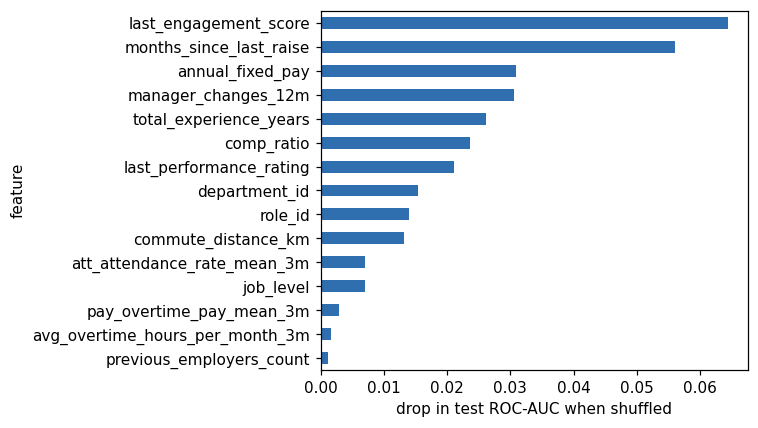

In [8]:
from sklearn.inspection import permutation_importance
mdl = joblib.load(P.MODELS / 'attrition_v2_train_only.joblib')
pi = permutation_importance(mdl, Xte, yte, scoring='roc_auc', n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({'feature': Xte.columns, 'auc_drop': pi.importances_mean, 'sd': pi.importances_std}).sort_values('auc_drop', ascending=False)
save_table(imp, P.task_dir(13) / 'permutation_importance.csv'); fig, ax = plt.subplots(figsize=(7, 4)); imp.head(15)[::-1].plot.barh(x='feature', y='auc_drop', ax=ax, legend=False, color='#2f6fb0'); ax.set_xlabel('drop in test ROC-AUC when shuffled'); plt.tight_layout(); plt.savefig(P.FIGURES / 'task13_permutation_importance.png', dpi=130, bbox_inches='tight'); imp.head(10).round(4)

## Stage 32: Fairness and Bias Evaluation

*What this stage is for:* Gaps between groups, measured with the protected attributes only after the fact.

Does v2 flag one group more than another? Gender and age come from the restricted `unlock_CX-15` file and are used **only here, for measurement**. They are not model inputs. Predictions for training rows are out-of-fold.

In [9]:
if 'group_gender' not in out: print('restricted file not present: group measurement skipped')
else:
    print(out['group_gender'].round(3).to_string()); print(out['group_age'].round(3).to_string())

   gender     n  actual_leave_rate  mean_predicted_risk  flagged_top10_share  recall_of_leavers_in_top10    auc
0  Female  1011              0.155                0.153                0.097                       0.261  0.705
1    Male  1311              0.139                0.155                0.104                       0.275  0.722
2   Other    61              0.164                0.153                0.082                       0.300  0.747
  age_band     n  actual_leave_rate  mean_predicted_risk  flagged_top10_share  recall_of_leavers_in_top10    auc
0    25-34  1468              0.144                0.153                0.097                       0.275  0.723
1    35-44   627              0.155                0.153                0.104                       0.258  0.700
2      45+    28              0.107                0.100                0.000                       0.000    NaN
3      <25   260              0.146                0.165                0.119                       

In [10]:
if 'group_gender' in out:
    g = out['group_gender']; a = out['group_age']; ok = a[a.n >= CFG['salary']['min_group_size']]
    print('flagged share by gender ranges %.3f to %.3f; by age band (groups with n >= %d) %.3f to %.3f; the company rule flags 10%% overall.' % (g.flagged_top10_share.min(), g.flagged_top10_share.max(), CFG['salary']['min_group_size'], ok.flagged_top10_share.min(), ok.flagged_top10_share.max()))
    print('Reading: small differences in flag rates can reflect real differences in the features (for example tenure), not unfairness. The 45+ group has only %d rows, too few for a conclusion.' % int(a[a.age_band == '45+'].n.iloc[0]))

flagged share by gender ranges 0.082 to 0.104; by age band (groups with n >= 30) 0.097 to 0.119; the company rule flags 10% overall.
Reading: small differences in flag rates can reflect real differences in the features (for example tenure), not unfairness. The 45+ group has only 28 rows, too few for a conclusion.


## Stage 33: Model Calibration or Prediction Reliability

*What this stage is for:* Are the numbers trustworthy as numbers?

Probabilities must be real probabilities: class-weighted models over-state risk, so calibration is learned inside the training folds and chosen by out-of-fold Brier score.

In [11]:
cal = out['calibration']; cal.round(4)

     method   brier     ece  roc_auc  pr_auc  mean_probability  base_rate
0      none  0.1895  0.2521   0.7170  0.3145            0.3985     0.1464
1   sigmoid  0.1144  0.0137   0.7170  0.3081            0.1540     0.1464
2  isotonic  0.1153  0.0144   0.7132  0.2963            0.1552     0.1464

chosen calibration: sigmoid | ECE 0.0137 (limit 0.05) -> OK


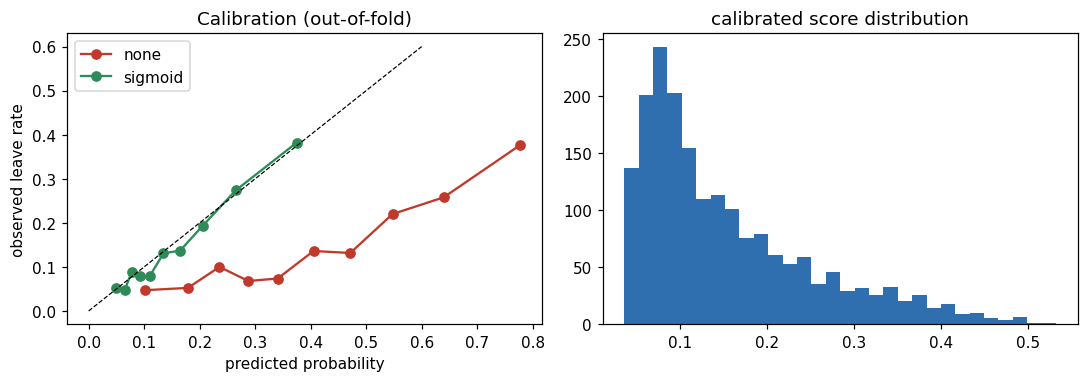

In [12]:
from sklearn.calibration import calibration_curve
CFG_A = CFG['attrition']['success_criteria']
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for k, c in (('none', '#c0392b'), (out['calibration_method'], '#2e8b57')):
    fr, mp = calibration_curve(ytr, out['oof'][k], n_bins=10, strategy='quantile'); ax[0].plot(mp, fr, 'o-', color=c, label=k)
ax[0].plot([0, .6], [0, .6], 'k--', lw=.8); ax[0].set_xlabel('predicted probability'); ax[0].set_ylabel('observed leave rate'); ax[0].legend(); ax[0].set_title('Calibration (out-of-fold)')
ax[1].hist(out['oof'][out['calibration_method']], bins=30, color='#2f6fb0'); ax[1].set_title('calibrated score distribution'); plt.tight_layout(); plt.savefig(P.FIGURES / 'task13_calibration.png', dpi=130, bbox_inches='tight')
e = cal.set_index('method').loc[out['calibration_method'], 'ece']; print('chosen calibration:', out['calibration_method'], '| ECE %.4f (limit %.2f) -> %s' % (e, CFG_A['max_expected_calibration_error'], 'OK' if e <= CFG_A['max_expected_calibration_error'] else 'ABOVE LIMIT'))

## Stage 34: Model Comparison and Final Selection

*What this stage is for:* Choose on evidence, not on the highest score alone.

Decision on evidence. The question is not 'which model has the highest number' but 'is the gain real, and is it worth the extra complexity'.

In [13]:
row = out['summary'].set_index('model'); b = row.loc['Logistic Regression (balanced) [baseline]']; v = row.loc['attrition-v2 candidate: LR + tuned HGB blend']; g = row.loc['HistGradientBoosting tuned']
tab = pd.DataFrame({'baseline LR': b, 'tuned gradient boosting': g, 'attrition-v2 (LR + HGB blend)': v})[0:0] if False else pd.DataFrame({'baseline LR': [b.roc_auc_mean, b.pr_auc_mean, b.recall_mean, b.brier_mean], 'tuned HGB alone': [g.roc_auc_mean, g.pr_auc_mean, g.recall_mean, g.brier_mean], 'attrition-v2 blend': [v.roc_auc_mean, v.pr_auc_mean, v.recall_mean, v.brier_mean]}, index=['roc_auc', 'pr_auc', 'recall', 'brier']).round(4); tab

         baseline LR  tuned HGB alone  attrition-v2 blend
roc_auc       0.7095           0.6948              0.7165
pr_auc        0.3245           0.3099              0.3250
recall        0.5843           0.5629              0.5842
brier         0.2000           0.1978              0.1895

In [14]:
allm = pd.concat([bench[['model', 'roc_auc_mean', 'roc_auc_sd', 'pr_auc_mean']].assign(source='programme reference'), out['summary'][['model', 'roc_auc_mean', 'roc_auc_sd', 'pr_auc_mean']].assign(source='this repo, same folds')], ignore_index=True)
allm = allm[~allm.model.str.contains('LEAKY')]; save_table(allm, P.task_dir(13) / 'comparison_with_benchmarks.csv'); allm.round(3)

                                          model  roc_auc_mean  roc_auc_sd  pr_auc_mean                 source
0                          Dummy (always stays)         0.500       0.000        0.146    programme reference
1   Logistic Regression (class_weight=balanced)         0.713       0.010        0.332    programme reference
2             Decision Tree (depth 4, balanced)         0.650       0.019        0.256    programme reference
3           Random Forest (300 trees, balanced)         0.715       0.018        0.336    programme reference
5                  HistGradientBoosting default         0.680       0.017        0.294  this repo, same folds
6                    HistGradientBoosting tuned         0.695       0.021        0.310  this repo, same folds
7     Logistic Regression (balanced) [baseline]         0.709       0.021        0.325  this repo, same folds
8      Random Forest (300, balanced) [baseline]         0.700       0.025        0.316  this repo, same folds
9  attriti

**Would I ship v2 if it were only slightly better but much harder to explain? No, not by itself.** A small gain inside the noise of five folds is not evidence of a better model, while a boosted ensemble is harder to explain to HR and to audit. I would ship the simpler logistic model for decisions and keep v2 as a challenger until a gain with a confidence interval above zero is shown on new data.

In [15]:
print('Gradient boosting alone vs baseline: ROC-AUC %+.4f (%s).' % (g.roc_auc_mean - b.roc_auc_mean, 'worse' if g.roc_auc_mean < b.roc_auc_mean else 'better')); print('Blend vs baseline: ROC-AUC %+.4f, PR-AUC %+.4f.' % (v.roc_auc_mean - b.roc_auc_mean, v.pr_auc_mean - b.pr_auc_mean))
print('Verdict:', out['verdict']['text']); print('Decision:', ('attrition-v2 beats the baseline with a gain that is real, and is saved and used in Task 14.' if out['verdict']['gain_is_meaningful'] else 'attrition-v2 is saved and used in Task 14 because the task asks for it, but HR should treat it as EQUIVALENT to the simpler logistic baseline, not as a proven upgrade. If only a slightly better but harder-to-explain model is on offer, the simple model is the better one to ship.'))

Gradient boosting alone vs baseline: ROC-AUC -0.0147 (worse).
Blend vs baseline: ROC-AUC +0.0070, PR-AUC +0.0005.
Verdict: Gain is NOT proven: the 95% interval of the paired fold difference includes 0 (or is below it), so the simpler baseline is not beaten.
Decision: attrition-v2 is saved and used in Task 14 because the task asks for it, but HR should treat it as EQUIVALENT to the simpler logistic baseline, not as a proven upgrade. If only a slightly better but harder-to-explain model is on offer, the simple model is the better one to ship.


## Stage 35: Final Prediction Generation

*What this stage is for:* Produce the deliverable.

Final predictions: test-set scores were produced above; here the 430 active employees are scored with the production model (refit on all labelled rows, calibrated). The risk report itself is Task 14.

In [16]:
prod = joblib.load(P.MODELS / 'attrition_v2.joblib'); sc, Xs, rep = V.load_scoring(); ps = prod.predict_proba(Xs)[:, 1]
res = pd.DataFrame({'employee_id': sc.employee_id.to_numpy(), 'risk_score_12m': ps.round(6)}); save_table(res, P.PREDICTIONS / 'attrition_v2_scores_2026.csv'); print(res.shape); res.risk_score_12m.describe().round(3).to_frame().T

(430, 2)


                count   mean    std    min    25%    50%   75%    max
risk_score_12m  430.0  0.127  0.091  0.026  0.058  0.095  0.18  0.453

## Stage 36: Output and Business Validation

*What this stage is for:* Check the output against the required format and read it as the user would.

Business sanity checks: probabilities in range, mean close to the historical base rate, and agreement with the simple baseline.

In [17]:
from scipy.stats import spearmanr
lr_cal = joblib.load(P.MODELS / 'attrition_v2_train_only.joblib'); base_lr = V.baseline_models()['Logistic Regression (balanced)'].fit(pd.concat([Xtr, Xte]), pd.concat([ytr, yte])).predict_proba(Xs)[:, 1]
top_v2, top_lr = set(res.employee_id[res.risk_score_12m >= res.risk_score_12m.quantile(.9)]), set(res.employee_id[base_lr >= np.quantile(base_lr, .9)])
print('probabilities within [0, 1]:', bool(res.risk_score_12m.between(0, 1).all()), '| mean score %.3f vs historical leave rate %.3f' % (res.risk_score_12m.mean(), y.mean()))
print('rank agreement with the baseline logistic model on the 430: spearman %.3f | overlap of the top 10%% lists: %d of %d' % (spearmanr(res.risk_score_12m, base_lr)[0], len(top_v2 & top_lr), len(top_v2)))

probabilities within [0, 1]: True | mean score 0.127 vs historical leave rate 0.146
rank agreement with the baseline logistic model on the 430: spearman 0.953 | overlap of the top 10% lists: 38 of 43


## Stage 37: Model Saving, Versioning and Reproducibility

*What this stage is for:* Artifacts, metadata, seeds, environment.

Versioned artifacts, metadata and a reproducibility check: reload, re-score, compare checksums.

In [18]:
import json; meta = json.load(open(P.METADATA / 'attrition_v2_metadata.json')); print({k: meta[k] for k in ('model_version', 'calibration_method', 'seed', 'train_rows', 'test_rows', 'production_fit_rows')}); print('environment:', meta['environment'])
ok = V.file_sha256(P.MODELS / 'attrition_v2.joblib') == meta['artifact_sha256']['attrition_v2.joblib']; again = joblib.load(P.MODELS / 'attrition_v2.joblib').predict_proba(Xs)[:, 1]
print('artifact checksum matches metadata:', ok, '| re-scoring gives identical probabilities:', bool(np.allclose(again, ps)), '| Phase 1/2 model files untouched:', sorted(p.name for p in (P.ROOT.parent / 'phase2' / 'models').glob('*.joblib'))[:3] if (P.ROOT.parent / 'phase2' / 'models').exists() else 'n/a')

{'model_version': 'attrition-v2', 'calibration_method': 'sigmoid', 'seed': 42, 'train_rows': 1906, 'test_rows': 477, 'production_fit_rows': 2383}
environment: {'python': '3.12.3', 'scikit-learn': '1.8.0', 'pandas': '3.0.2', 'numpy': '2.4.4', 'scipy': '1.17.1', 'optional_libraries': {'lightgbm': None, 'xgboost': None, 'shap': None}}
artifact checksum matches metadata: True | re-scoring gives identical probabilities: True | Phase 1/2 model files untouched: ['attendance_detector_v2.joblib', 'chatbot_intent_model_augmented.joblib', 'chatbot_intent_model_v1.joblib']


## Stage 38: Final Findings, Limitations and Conclusion

*What this stage is for:* What was found, what remains, what must not be done with it.

In [19]:
print('FINDINGS'); print('- Same-fold ROC-AUC: baseline LR %.3f, tuned gradient boosting %.3f, attrition-v2 blend %.3f.' % (b.roc_auc_mean, g.roc_auc_mean, v.roc_auc_mean))
print('- %s' % out['verdict']['text']); print('- Calibration fixed a large over-statement of risk (mean uncalibrated %.2f vs base rate %.2f): ECE %.3f -> %.3f.' % (cal.set_index('method').loc['none', 'mean_probability'], y.mean(), cal.set_index('method').loc['none', 'ece'], cal.set_index('method').loc[out['calibration_method'], 'ece']))
print('LIMITS: 2,383 labelled rows and about 350 leavers; five folds give wide uncertainty; the monthly features cover only recent months; the model supports HR conversations and must not be used for dismissal, pay or promotion decisions.')

FINDINGS
- Same-fold ROC-AUC: baseline LR 0.709, tuned gradient boosting 0.695, attrition-v2 blend 0.716.
- Gain is NOT proven: the 95% interval of the paired fold difference includes 0 (or is below it), so the simpler baseline is not beaten.
- Calibration fixed a large over-statement of risk (mean uncalibrated 0.40 vs base rate 0.15): ECE 0.252 -> 0.014.
LIMITS: 2,383 labelled rows and about 350 leavers; five folds give wide uncertainty; the monthly features cover only recent months; the model supports HR conversations and must not be used for dismissal, pay or promotion decisions.
